# Chapter 3: The Most Useful Wrong Answer

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will test claims one case at a time. You will see why a single allowed case is enough to send the word "always" back for revision, why the same calculation can break one claim and leave another alone, how consecutive odd numbers build squares, and how counting leftovers explains why two odd numbers always add to an even one.

**A note before you start.** The code cells are optional reading. You do not need to run or understand them: the numbers and pictures they produce are already shown right below each one. If you are curious, read the code like a recipe, one line at a time.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch

INK, TEAL, GOLD, RED, GREY, NAVY = "#172a3b", "#0f6268", "#b8860b", "#a24a33", "#6b757b", "#1f3b5c"
PALE, PICK = "#e3efee", "#f3e1da"
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.edgecolor": GREY,
                     "axes.labelcolor": INK, "text.color": INK})

def blank(ax):
    """Hide ticks and frame so a drawing looks like a drawing."""
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

def as_set(items):
    """Write a collection the way the book does: {3, 6, 9}."""
    items = list(items)
    return "{" + ", ".join(str(i) for i in items) + "}" if items else "{ }"

yn = lambda b: "yes" if b else "no"

## 1. One allowed case is enough

**The question.** Does multiplication always make a number bigger?

**The equation from the chapter.**

$$7 \times 0 = 0$$

**What the symbols mean.** The starting number is 7. The multiplier is the second factor. "Always" means *every* allowed multiplier, and the claim as written puts no limit on it. We start with the multiplier 0.

**Try to predict first.** Before trying 1: is $7 \times 1$ bigger than 7?

In [2]:
start = 7

def test_multiplier(m):
    result = start * m
    if result > start:
        role = "supports the claim (but agreement is not proof)"
    else:
        role = "counterexample"
    return result, role

m = 0
result, role = test_multiplier(m)
print("Claim: multiplication always makes a number bigger.")
print(f"Is the case allowed? The claim sets no limit on the multiplier, so {m} is allowed.")
print(f"Is the arithmetic right? {start} x {m} = {result}   (yes)")
print(f"Compare with the start: {result} versus {start}, so {result} is {'bigger' if result > start else 'not bigger'} than {start}")
print("Verdict:", role)
print()
print(f"{'Multiplier':12s}{'Calculation':14s}{'Compared with 7':18s}Verdict")
for m in [0, 1, 2, 4]:
    r, role = test_multiplier(m)
    cmp = "bigger" if r > start else ("the same size" if r == start else "smaller")
    print(f"{m:<12d}{start} x {m} = {r:<5d}{cmp:18s}{role}")

Claim: multiplication always makes a number bigger.
Is the case allowed? The claim sets no limit on the multiplier, so 0 is allowed.
Is the arithmetic right? 7 x 0 = 0   (yes)
Compare with the start: 0 versus 7, so 0 is not bigger than 7
Verdict: counterexample

Multiplier  Calculation   Compared with 7   Verdict
0           7 x 0 = 0    smaller           counterexample
1           7 x 1 = 7    the same size     counterexample
2           7 x 2 = 14   bigger            supports the claim (but agreement is not proof)
4           7 x 4 = 28   bigger            supports the claim (but agreement is not proof)


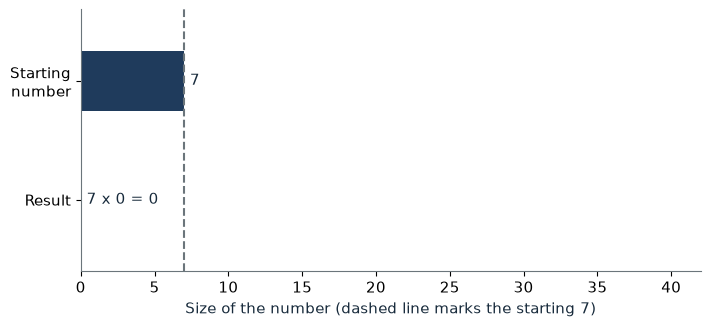

In [3]:
m = 0
result, role = test_multiplier(m)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh([1], [start], color=NAVY, height=0.5)
ax.barh([0], [result], color=RED, height=0.5)
ax.text(start + 0.4, 1, f"{start}", va="center")
ax.text(result + 0.4, 0, f"{start} x {m} = {result}", va="center")
ax.axvline(start, color=GREY, linestyle="dashed")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Result", "Starting\nnumber"])
ax.set_xlim(0, 42); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Size of the number (dashed line marks the starting 7)")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.show()

**What this shows.** $7 \times 0 = 0$, which is smaller than 7. The claim allowed a multiplier of 0, so this is a counterexample. Other multipliers behave differently: $7 \times 1 = 7$ is the same size (also a counterexample, since the claim says *bigger*), while $7 \times 2 = 14$ and $7 \times 4 = 28$ agree with the claim. Many agreeing cases still do not prove it. When a sentence says always, every, or all, try the smallest allowed cases first: zero and one end many overconfident sentences. The counterexample points at the sentence that promised too much, never at the person who wrote it.

**Where it stops working.** This tests the claim as written, with no condition on either factor. The arithmetic must be correct for a case to count.

## 2. Same calculation, different domain

**The question.** Why does $1 \times 1 = 1$ disprove one squaring claim but not the other?

**The equations from the chapter.**

$$1 \times 1 = 1 \qquad\qquad 2 \times 2 = 4 > 2$$

**What the symbols mean.** Squaring a whole number means multiplying it by itself. The *domain* is the set of cases a claim agreed to handle. Claim A: "for whole numbers greater than one, squaring gives a larger number." Claim B: "for every whole number, squaring gives a larger number." We start by testing $n = 1$ against Claim A.

**Try to predict first.** Keep $1 \times 1 = 1$ and switch to Claim B. Does the verdict change even though the arithmetic does not?

In [4]:
def judge(n, claim):
    square = n * n
    allowed = (n > 1) if claim == "greater than one" else True
    larger = square > n
    if not allowed:
        return square, allowed, larger, "not a counterexample (outside the domain)"
    return square, allowed, larger, ("supports the claim (not a proof)" if larger else "counterexample")

n, claim = 1, "greater than one"
square, allowed, larger, verdict = judge(n, claim)
print(f"Claim A: for whole numbers greater than one, squaring gives a larger number.")
print(f"Arithmetic: {n} x {n} = {square}   (correct)")
print(f"Allowed by the claim? Is {n} > 1?  {'yes' if allowed else 'no'}")
print(f"Larger than the start? {square} > {n}?  {'yes' if larger else 'no'}")
print("Verdict:", verdict)
print()
n, claim = 1, "every whole number"
square, allowed, larger, verdict = judge(n, claim)
print("Claim B: for every whole number, squaring gives a larger number.")
print(f"Arithmetic: {n} x {n} = {square}   (same arithmetic)")
print(f"Allowed by the claim? Every whole number is allowed, so yes")
print(f"Larger than the start? {square} > {n}?  {'yes' if larger else 'no'}")
print("Verdict:", verdict)

Claim A: for whole numbers greater than one, squaring gives a larger number.
Arithmetic: 1 x 1 = 1   (correct)
Allowed by the claim? Is 1 > 1?  no
Larger than the start? 1 > 1?  no
Verdict: not a counterexample (outside the domain)

Claim B: for every whole number, squaring gives a larger number.
Arithmetic: 1 x 1 = 1   (same arithmetic)
Allowed by the claim? Every whole number is allowed, so yes
Larger than the start? 1 > 1?  no
Verdict: counterexample


All eight combinations from the reader's menu:

In [5]:
print(f"{'n':4s}{'n x n':12s}{'Claim A (n > 1)':44s}Claim B (every whole number)")
for n in [0, 1, 2, 3]:
    sq, _, _, va = judge(n, "greater than one")
    _, _, _, vb = judge(n, "every whole number")
    print(f"{n:<4d}{n} x {n} = {sq:<5d}{va:44s}{vb}")

n   n x n       Claim A (n > 1)                             Claim B (every whole number)
0   0 x 0 = 0    not a counterexample (outside the domain)   counterexample
1   1 x 1 = 1    not a counterexample (outside the domain)   counterexample
2   2 x 2 = 4    supports the claim (not a proof)            supports the claim (not a proof)
3   3 x 3 = 9    supports the claim (not a proof)            supports the claim (not a proof)


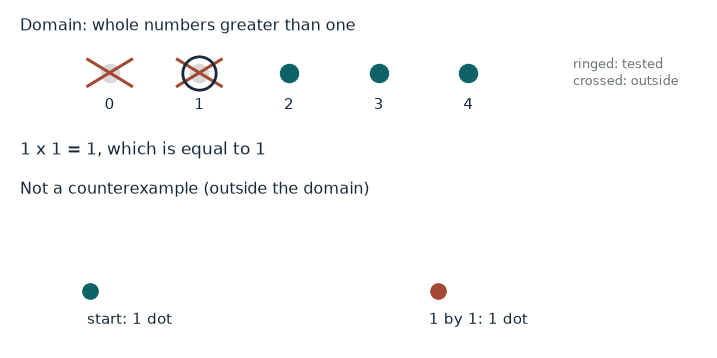

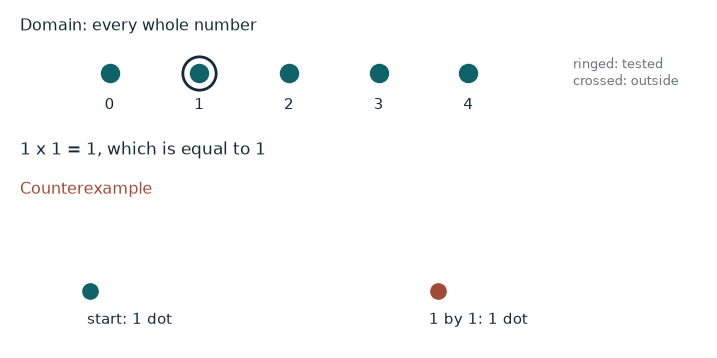

In [6]:
def squaring_figure(n, claim):
    square, allowed, larger, verdict = judge(n, claim)
    fig, ax = plt.subplots(figsize=(9, 4.4))
    domain = "whole numbers greater than one" if claim == "greater than one" else "every whole number"
    ax.text(-0.5, 5.25, f"Domain: {domain}", fontsize=11.5)
    for k in range(5):
        x = 0.4 + 0.9 * k
        inside = claim == "every whole number" or k > 1
        ax.plot([x], [4.55], "o", markersize=13, color=TEAL if inside else "#d9d9d9", zorder=3)
        if not inside:
            ax.plot([x - 0.22, x + 0.22], [4.33, 4.77], color=RED, linewidth=2.2, zorder=4)
            ax.plot([x - 0.22, x + 0.22], [4.77, 4.33], color=RED, linewidth=2.2, zorder=4)
        if k == n:
            ax.plot([x], [4.55], "o", markersize=24, markerfacecolor="none", markeredgecolor=INK, markeredgewidth=2, zorder=5)
        ax.text(x, 3.95, str(k), ha="center")
    ax.text(5.05, 4.55, "ringed: tested\ncrossed: outside", fontsize=9.5, color=GREY, va="center")
    ax.text(-0.5, 3.2, f"{n} x {n} = {square}, which is {'larger than' if larger else 'equal to'} {n}", fontsize=12.5)
    step = 0.42
    for i in range(n):
        ax.plot([0.2 + step * i], [0.95], "o", markersize=11, color=TEAL)
    for r in range(n):
        for c in range(n):
            ax.plot([3.7 + step * c], [0.95 + step * r], "o", markersize=11, color=TEAL if larger else RED)
    ax.text(0.6, 0.4, f"start: {n} dot{'' if n == 1 else 's'}", ha="center")
    ax.text(4.1, 0.4, f"{n} by {n}: {square} dot{'' if square == 1 else 's'}", ha="center")
    ax.text(-0.5, 2.55, verdict.capitalize(), fontsize=11.5, color=RED if verdict == "counterexample" else INK)
    ax.set_xlim(-0.6, 6.4); ax.set_ylim(0, 5.6)
    blank(ax)
    plt.show()

squaring_figure(1, "greater than one")
squaring_figure(1, "every whole number")

**What this shows.** The domain strip marks which cases the claim agreed to handle. A case outside the domain cannot refute the claim, however correct its arithmetic. Inside the domain, a result that is not strictly larger is a counterexample. So $1 \times 1 = 1$ does nothing to Claim A (1 is not greater than 1) but disproves Claim B at once. A good counterexample report has three parts: quote the claim, show the case is allowed, and show the conflicting result.

**Where it stops working.** Whole numbers only, and "larger" means *strictly* larger. If the claim said "at least as large," then 0 and 1 would agree with it, because equality counts.

## 3. Odd numbers that build squares

**The question.** What do $1 + 3$, $1 + 3 + 5$, and $1 + 3 + 5 + 7$ have in common?

**The equation from the chapter.**

$$1 + 3 + 5 + 7 = 16$$

**What the symbols mean.** The odd numbers 1, 3, 5, 7, 9 are added in order, starting from 1. Each colour in the picture is one odd number of tiles. A *square number* is a whole number times itself. We start with four odd numbers.

**Try to predict first.** What is $1 + 3 + 5 + 7 + 9$ before you calculate it?

In [7]:
def odd_sum(terms):
    odds = [2 * k + 1 for k in range(terms)]
    return odds, sum(odds)

terms = 4
odds, total = odd_sum(terms)
running = 0
for o in odds:
    running += o
    print(f"  add {o}: running total {running}")
print(f"{' + '.join(map(str, odds))} = {total}")
print(f"{terms} x {terms} = {terms * terms}")
print(f"The new odd number {odds[-1]} = {terms - 1} + {terms - 1} + 1 wraps the old {terms - 1} by {terms - 1} square into a {terms} by {terms} square.")
print()
print(f"{'Odd numbers':20s}{'Total':8s}Square")
for t in [2, 3, 4, 5]:
    o, s = odd_sum(t)
    print(f"{' + '.join(map(str, o)):20s}{s:<8d}{t} x {t} = {t * t}")

  add 1: running total 1
  add 3: running total 4
  add 5: running total 9
  add 7: running total 16
1 + 3 + 5 + 7 = 16
4 x 4 = 16
The new odd number 7 = 3 + 3 + 1 wraps the old 3 by 3 square into a 4 by 4 square.

Odd numbers         Total   Square
1 + 3               4       2 x 2 = 4
1 + 3 + 5           9       3 x 3 = 9
1 + 3 + 5 + 7       16      4 x 4 = 16
1 + 3 + 5 + 7 + 9   25      5 x 5 = 25


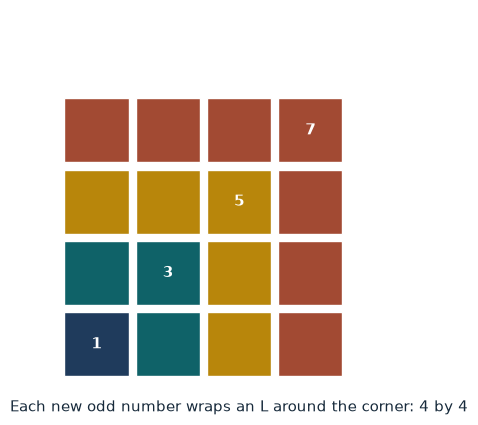

In [8]:
terms = 4
odds, total = odd_sum(terms)
colours = [NAVY, TEAL, GOLD, RED, "#6b7a2b"]
fig, ax = plt.subplots(figsize=(5, 5))
for k in range(terms):
    cells_k = [(k, j) for j in range(k + 1)] + [(i, k) for i in range(k)]
    for x, y in cells_k:
        ax.add_patch(Rectangle((x + 0.05, y + 0.05), 0.9, 0.9, facecolor=colours[k], edgecolor="white"))
    ax.text(k + 0.5, k + 0.5, str(odds[k]), ha="center", va="center", color="white", fontweight="bold")
ax.set_xlim(-0.2, 5.2); ax.set_ylim(-0.2, 5.2); ax.set_aspect("equal")
blank(ax)
ax.set_xlabel(f"Each new odd number wraps an L around the corner: {terms} by {terms}")
plt.show()

**What this shows.** $1 + 3 + 5 + 7 = 16 = 4 \times 4$. Each new odd number is an L shape that wraps around the corner of the square already built, making a square one tile wider on each side. The sums for two, three, four, and five odd numbers are 4, 9, 16, and 25. Written as a *conjecture*, the pattern says the sum of the first $n$ odd numbers is $n \times n$. Every example agrees, but checked examples alone do not prove every case.

**Where it stops working.** The odd numbers must be consecutive and start from 1. Leave one out or start from 3 and the pattern breaks: $3 + 5 = 8$ is not a square.

## 4. Two leftovers make a pair

**The question.** Why is the sum of two odd whole numbers always even?

**The equation from the chapter.**

$$5 + 3 = 8$$

**What the symbols mean.** An even number splits completely into pairs. An odd number is pairs plus one leftover tile. In the picture, boxed groups are pairs and red tiles are leftovers. We start with rows of 5 and 3 tiles.

**Try to predict first.** Change the second row from 3 to 4 tiles. Will the total have a leftover tile?

In [9]:
def pairs(count):
    p, left = divmod(count, 2)
    return p, left

def show(first, second):
    p1, l1 = pairs(first); p2, l2 = pairs(second)
    total = first + second
    pt, lt = pairs(total)
    print(f"{first} = {p1} x 2 + {l1}     {second} = {p2} x 2 + {l2}")
    print(f"{first} + {second} = {total}")
    print(f"Pairs: {p1} + {p2} = {p1 + p2}.  Leftovers: {l1} + {l2} = {l1 + l2}.")
    if l1 + l2 == 2:
        print("The two leftovers join to make one more pair, so no tile is left over.")
    elif l1 + l2 == 1:
        print("Only one row has a leftover, and nothing joins it, so one tile stays unpaired.")
    else:
        print("Both rows are already all pairs, so the pairs simply remain pairs.")
    print(f"{total} = {pt} x 2 + {lt}, so the total is {'even' if lt == 0 else 'odd'}.")
    print()

show(5, 3)
print("Other rows from the menu:")
for f, s in [(5, 4), (7, 3), (6, 3), (7, 4), (6, 4)]:
    show(f, s)

5 = 2 x 2 + 1     3 = 1 x 2 + 1
5 + 3 = 8
Pairs: 2 + 1 = 3.  Leftovers: 1 + 1 = 2.
The two leftovers join to make one more pair, so no tile is left over.
8 = 4 x 2 + 0, so the total is even.

Other rows from the menu:
5 = 2 x 2 + 1     4 = 2 x 2 + 0
5 + 4 = 9
Pairs: 2 + 2 = 4.  Leftovers: 1 + 0 = 1.
Only one row has a leftover, and nothing joins it, so one tile stays unpaired.
9 = 4 x 2 + 1, so the total is odd.

7 = 3 x 2 + 1     3 = 1 x 2 + 1
7 + 3 = 10
Pairs: 3 + 1 = 4.  Leftovers: 1 + 1 = 2.
The two leftovers join to make one more pair, so no tile is left over.
10 = 5 x 2 + 0, so the total is even.

6 = 3 x 2 + 0     3 = 1 x 2 + 1
6 + 3 = 9
Pairs: 3 + 1 = 4.  Leftovers: 0 + 1 = 1.
Only one row has a leftover, and nothing joins it, so one tile stays unpaired.
9 = 4 x 2 + 1, so the total is odd.

7 = 3 x 2 + 1     4 = 2 x 2 + 0
7 + 4 = 11
Pairs: 3 + 2 = 5.  Leftovers: 1 + 0 = 1.
Only one row has a leftover, and nothing joins it, so one tile stays unpaired.
11 = 5 x 2 + 1, so the tota

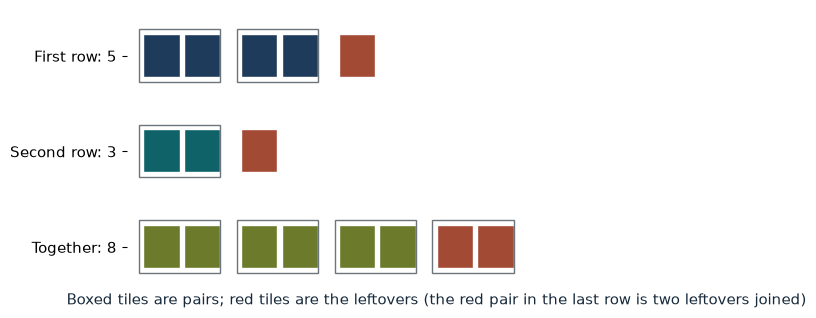

In [10]:
def row(ax, y, count, colour, joined=False):
    x = 0.0
    p, left = divmod(count, 2)
    for i in range(p):
        c = RED if joined and i == p - 1 else colour
        for t in range(2):
            ax.add_patch(Rectangle((x + t * 0.5, y), 0.45, 0.45, facecolor=c, edgecolor="white"))
        ax.add_patch(Rectangle((x - 0.05, y - 0.05), 1.0, 0.55, fill=False, edgecolor=GREY))
        x += 1.2
    if left:
        ax.add_patch(Rectangle((x, y), 0.45, 0.45, facecolor=RED, edgecolor="white"))

first, second = 5, 3
fig, ax = plt.subplots(figsize=(8, 3.6))
row(ax, 2.2, first, NAVY)
row(ax, 1.2, second, TEAL)
row(ax, 0.2, first + second, "#6b7a2b", joined=True)
ax.set_xlim(-0.2, 7.4); ax.set_ylim(0, 2.9)
ax.set_xticks([]); ax.set_yticks([0.42, 1.42, 2.42])
ax.set_yticklabels([f"Together: {first + second}", f"Second row: {second}", f"First row: {first}"])
for s in ax.spines.values(): s.set_visible(False)
ax.set_xlabel("Boxed tiles are pairs; red tiles are the leftovers (the red pair in the last row is two leftovers joined)")
plt.show()

**What this shows.** $5 + 3 = 8$. Each odd row brings exactly one leftover tile, so $1 + 1 = 2$ leftovers, and two leftovers join into one more pair. That works whatever the rows' lengths, so the argument covers every pair of odd numbers, not just 5 and 3. This is the difference between examples that agree (the odd-numbers pattern) and a reason that covers every case. To explain why a parity claim holds, count leftovers instead of trying more examples.

**Where it stops working.** The tiles are whole numbers. The reason works because every odd number has the same structure: pairs plus one leftover. An odd row plus an even row has only one leftover, so that total is odd (for example $5 + 4 = 9$).

## Practice

**1.** Is $6 \times 1 = 6$ a counterexample to "multiplication always makes a number bigger"?

<details><summary>Show answer</summary>

Check three things in order.

- Allowed? Nothing in the claim excludes 1, so yes.
- Arithmetic right? $6 \times 1 = 6$, yes.
- Conflict? 6 is not bigger than 6.

So yes, it is a counterexample.
</details>

**2.** Is $0 \times 0 = 0$ a counterexample to "for whole numbers greater than one, squaring gives a larger number"?

<details><summary>Show answer</summary>

- Arithmetic: $0 \times 0 = 0$ is correct.
- Allowed? Is 0 greater than one? No. So the case is outside the domain.

Not a counterexample to that claim. It *does* disprove the "every whole number" claim, since 0 is not larger than 0.
</details>

**3.** What is $1 + 3 + 5 + 7 + 9 + 11$, and which square is it? Using leftovers, is $7 + 9$ even or odd?

<details><summary>Show answer</summary>

Running total: $1 + 3 = 4$, $4 + 5 = 9$, $9 + 7 = 16$, $16 + 9 = 25$, $25 + 11 = 36$.

Six odd numbers, so the square is $6 \times 6 = 36$.

For $7 + 9$: each odd row has one leftover, $1 + 1 = 2$ leftovers make one pair, so $7 + 9 = 16$ is even.
</details>